# Support Vector Machines (SVM)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/06_SVM.ipynb)

In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
from ipywidgets import interact
from sklearn import svm
from sklearn.datasets import make_blobs
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
import sklearn.metrics as mt

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Geometric Foundations of Separating Hyperplanes

- For binary classification with targets $t_n \in \{-1, +1\}$, we seek a linear decision surface (separate bias, $\mathbf{x}, \mathbf{w} \in \mathbb{R}^D$)

$$
y(\mathbf{x}) = \mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0
$$

  and classify a point by the sign of $y(\mathbf{x})$.

> 💡 **Key Takeaway:** Rather than finding *any* arbitrary separating boundary, Support Vector Machines find the hyperplane that maximizes the **geometric margin**—the distance to the closest training observations.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 9: Support Vector Machines. Springer](https://doi.org/10.1007/978-3-031-38747-0_9)*</small>

### Extending Beyond Linear Separability

- Real-world datasets are rarely perfectly linearly separable.
- Support Vector Machines address this via two key mechanisms:
  1. **Soft Margins (Slack Variables $\xi_n$)**: tolerate some margin violations and classification errors, at a price set by the parameter $C$.
  2. **The Kernel Trick**: implicitly map inputs into high-dimensional feature spaces where a linear boundary separates the classes much better.

### Hyperplanes & Decision Surfaces

- Recall the linear decision boundary of the single-layer perceptron *(from Lecture 04)*.
- In a $D$-dimensional space, a **hyperplane** is an affine flat subspace of dimension $D-1$:
  - $D = 2$: a straight line.
  - $D = 3$: a flat 2D plane.
  - $D > 3$: a $(D-1)$-dimensional linear manifold.

- Mathematical definition defined by weight vector $\mathbf{w} \in \mathbb{R}^D$ and bias $w_0 \in \mathbb{R}$:

$$
\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0
$$


### Separating Hyperplanes & Decision Rules

- A hyperplane divides feature space into two half-spaces:
  - $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 > 0$: assigns class $+1$.
  - $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 < 0$: assigns class $-1$.

- For linearly separable training points $\{(\mathbf{x}_n, t_n)\}_{n=1}^N$ with $t_n \in \{-1, +1\}$, a separating hyperplane satisfies:

$$
t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) > 0, \quad \forall n = 1, \dots, N
$$


In [2]:
# Linearly separable synthetic data: two Gaussian clusters
X, y = make_blobs(n_samples=40, centers=2, cluster_std=(1, 1), random_state=3)
xlim, ylim = hp.get_boundaries(X)

# The maximal margin classifier: a linear SVM with a (practically) infinite penalty C
svm_max_margin = svm.SVC(kernel="linear", C=1e6).fit(X, y)
xx, yy, grid = hp.create_2d_grid(X)
Z_max_margin = svm_max_margin.decision_function(grid).reshape(xx.shape)      # y(x) = w^T x + w_0 on the plotting grid

In [3]:
def plot_separating_lines(show_svm=False):
    """Two hand-drawn candidate lines, or the maximal margin hyperplane fitted above."""
    if show_svm:
        hp.plot_svm_panels({"Maximal margin hyperplane": (X, y, xx, yy, Z_max_margin, svm_max_margin.support_vectors_)}, figsize=(5.5, 5.0))
    else:
        hp.plot_svm_separating_plane(X, y, xlim, ylim)

In [4]:
interact(plot_separating_lines, show_svm=False);

interactive(children=(Checkbox(value=False, description='show_svm'), Output()), _dom_classes=('widget-interact…

### Vector Norms & Orthogonal Distance

- The perpendicular distance from observation $\mathbf{x}_n$ to hyperplane $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0$ is:

$$
\text{dist}(\mathbf{x}_n) = \frac{t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0)}{\|\mathbf{w}\|}
$$

- Here $\|\mathbf{w}\| = \sqrt{\sum_{i=1}^{D} w_i^2}$ represents the Euclidean ($L_2$) norm of the normal vector.
- This signed distance is positive for correctly classified points; in general the distance is $\lvert \mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0 \rvert / \|\mathbf{w}\|$.

## 2. The Maximal Margin Classifier

- The **margin** $M$ is the minimum distance from the separating hyperplane to any training sample.
- We formulate the optimization to maximize margin $M$:

$$
\max_{\mathbf{w}, w_0, M} M \quad \text{subject to } \frac{t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0)}{\|\mathbf{w}\|} \ge M, \quad \forall n
$$

- Fixing $M \|\mathbf{w}\| = 1$, maximizing $M = \frac{1}{\|\mathbf{w}\|}$ is equivalent to minimizing $\frac{1}{2}\|\mathbf{w}\|^2$:

$$
\min_{\mathbf{w}, w_0} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to } t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) \ge 1, \quad \forall n = 1, \dots, N
$$


### Support Vectors & Margin Constraints

- Points satisfying $t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) = 1$ lie precisely on the margin boundary.
- These critical boundary observations are called **support vectors**.

> 💡 **Key Takeaway:** The optimal decision boundary depends solely on the support vectors. Moving or removing any other data point does not change the boundary, as long as the point stays outside the margin.

$\mathbf{w} = (-0.589, -0.157)^\mathrm{T}$, $w_0 = -0.600$, margin $M = 1/\|\mathbf{w}\| = 1.640$; support vectors per class: [2 1]

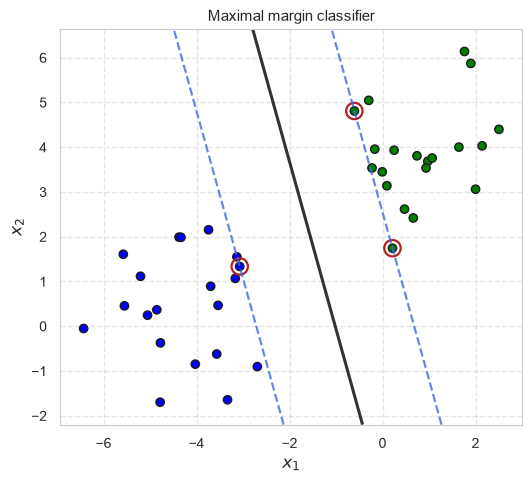

In [5]:
w, w_0 = svm_max_margin.coef_[0], svm_max_margin.intercept_[0]
display(Markdown(rf"$\mathbf{{w}} = ({w[0]:.3f}, {w[1]:.3f})^\mathrm{{T}}$, $w_0 = {w_0:.3f}$, margin $M = 1/\|\mathbf{{w}}\| = {1 / np.linalg.norm(w):.3f}$; "
                 f"support vectors per class: {svm_max_margin.n_support_}"))
hp.plot_svm_panels({"Maximal margin classifier": (X, y, xx, yy, Z_max_margin, svm_max_margin.support_vectors_)}, figsize=(5.5, 5.0))

## 3. Soft-Margin Support Vector Classifier

### The Need for Soft Margins

- Strict maximal margin classification fails when:
  - The training data are not linearly separable.
  - Outliers or noise cause severe overfitting and dramatically shrink the margin.

- **Solution**: Introduce non-negative **slack variables** $\xi_n \ge 0$ allowing points to penetrate the margin.


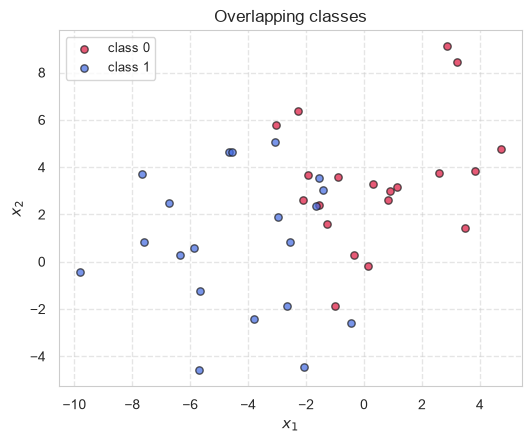

In [6]:
# Two overlapping Gaussian clusters: no separating hyperplane exists
X_m, y_m = make_blobs(n_samples=40, centers=2, cluster_std=(2.5, 2.5), random_state=3)
hp.plot_classes_2d(X_m, y_m, title="Overlapping classes", figsize=(5.5, 4.6))

### Optimization with Slack Variables

- Slack variable interpretation for observation $n$:
  - $\xi_n = 0$: sample is correctly classified on or outside the margin.
  - $0 < \xi_n \le 1$: sample penetrates the margin but remains on the correct side.
  - $\xi_n > 1$: sample crosses the decision boundary (misclassified).

- **Support vectors** are now all samples on the margin or on its wrong side ($\xi_n > 0$); only they determine the boundary.
- **Primal Objective with Soft Margin**:

$$
\min_{\mathbf{w}, w_0, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{n=1}^{N} \xi_n \quad \text{subject to } t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) \ge 1 - \xi_n, \quad \xi_n \ge 0
$$

### The Regularization Parameter $C$

- The hyperparameter $C > 0$ weights the slack penalty $C \sum_{n=1}^N \xi_n$ in the primal objective (the formulation used by `sklearn.svm.SVC`) and controls the trade-off between margin size and slack violations:
  - **Large $C$**: Heavy penalty on slack violations $\xi_n$. Yields narrow margins, closely fitting training data (low bias, high variance).
  - **Small $C$**: Permits greater slack violations. Yields wider margins and smoother boundaries (higher bias, lower variance).
- $C$ acts like $1/\lambda$ of ridge regression (Lecture 02): a *large* $C$ means *little* regularization.

> ⚠️ **Important:** Some textbooks, e.g. James et al., use $C$ for the opposite quantity: a *budget* for the total slack, so that a larger $C$ there means a *wider* margin. Here and in scikit-learn, $C$ is the penalty.

> 📝 **Note:** Standardize features measured in different units before training an SVM; otherwise the features with larger scales dominate the margin.

### Empirical Effect of the Regularization Parameter $C$

- Linear SVMs fitted to the overlapping clusters for $C \in \{1, 0.5, 0.25, 0.01\}$: the margin widens as $C$ decreases.

   C  margin 1/||w||  support vectors  training accuracy
1.00           0.888               14              0.875
0.50           1.000               14              0.875
0.25           1.357               16              0.875
0.01           3.410               26              0.875


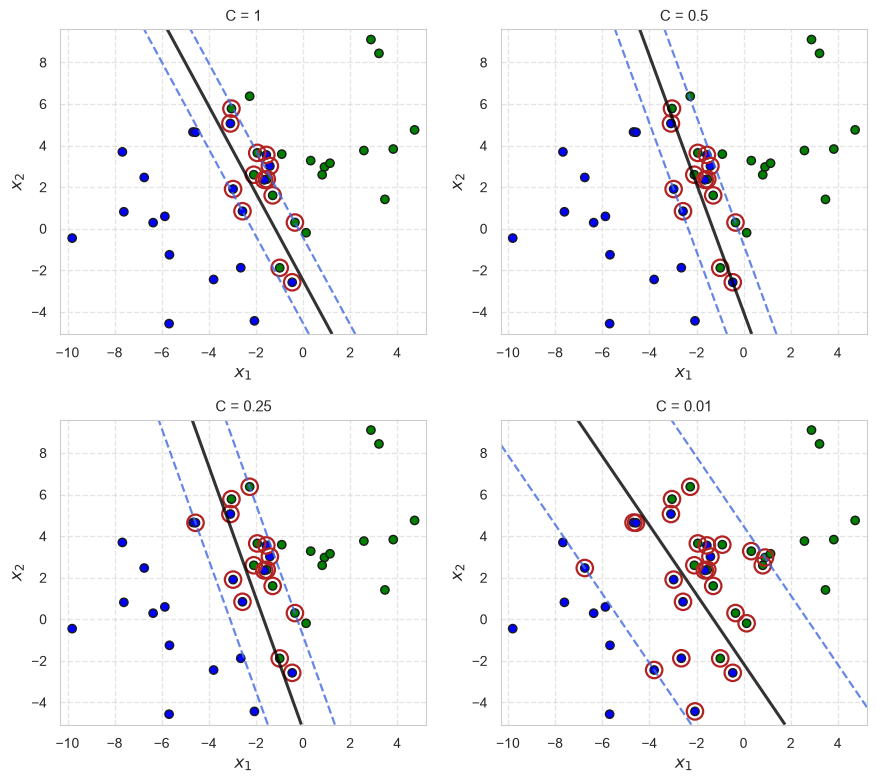

In [7]:
xx_m, yy_m, grid_m = hp.create_2d_grid(X_m)
panels, rows = {}, []
for C_value in [1, 0.5, 0.25, 0.01]:
    model = svm.SVC(kernel="linear", C=C_value).fit(X_m, y_m)
    Z = model.decision_function(grid_m).reshape(xx_m.shape)
    panels[f"C = {C_value}"] = (X_m, y_m, xx_m, yy_m, Z, model.support_vectors_)
    rows.append({"C": C_value, "margin 1/||w||": 1 / np.linalg.norm(model.coef_), "support vectors": model.n_support_.sum(),
                 "training accuracy": model.score(X_m, y_m)})
print(pd.DataFrame(rows).round(3).to_string(index=False))
hp.plot_svm_panels(panels, figsize=(9, 8))

## 4. Non-Linear Decision Boundaries & The Kernel Trick
- Problem:
    + When the true class boundary is non-linear, no linear boundary fits it, with or without soft margins.
    + Example: three Gaussian clusters, where the outer two form class $1$; a linear SVM does no better than always predicting the larger class.

Linear SVM training accuracy 0.667; always predicting the larger class 0.667

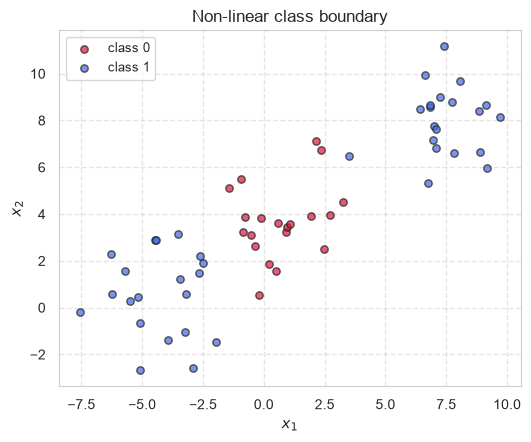

In [8]:
# Three Gaussian clusters; clusters 0 and 2 together form class 1, cluster 1 is class 0
X_h, y_h3, centers_h = make_blobs(n_samples=60, centers=3, cluster_std=1.5, random_state=3, return_centers=True)
y_h = np.where(y_h3 == 2, 1, y_h3)
linear_h = svm.SVC(kernel="linear").fit(X_h, y_h)
display(Markdown(f"Linear SVM training accuracy {linear_h.score(X_h, y_h):.3f}; always predicting the larger class {max(y_h.mean(), 1 - y_h.mean()):.3f}"))
hp.plot_classes_2d(X_h, y_h, title="Non-linear class boundary", figsize=(5.5, 4.6))

### Non-Linear Feature Space Expansion

- Solution:
    + Enlarge the space of features using different transformations, like $x_1, x_1^2, x_1^3, x_1 x_2, x_2, \dots$
    + Fit a support-vector classifier in the enlarged space
- This procedure results in non-linear decision boundaries in the original space

### The Kernel Trick

- The fitted SVM can be written using inner products with the training points only, and only the support vectors $\mathcal{S}$ get a non-zero weight $a_n$:

$$
y(\mathbf{x}) = w_0 + \sum_{n \in \mathcal{S}} a_n\, k(\mathbf{x}, \mathbf{x}_n)
$$

- With the **linear kernel** $k(\mathbf{x}, \mathbf{x}') = \mathbf{x}^\mathrm{T}\mathbf{x}'$ this is the support vector classifier of §3.
- **The Kernel Trick**: replace the inner product by a kernel $k(\mathbf{x}, \mathbf{x}') = \boldsymbol{\phi}(\mathbf{x})^\mathrm{T} \boldsymbol{\phi}(\mathbf{x}')$, which computes an inner product in a high-dimensional feature space without ever constructing $\boldsymbol{\phi}(\mathbf{x})$.
- **Polynomial Kernel**: $k(\mathbf{x}, \mathbf{x}') = (\mathbf{x}^\mathrm{T}\mathbf{x}' + c)^d$, where $d \in \mathbb{N}$ is the polynomial degree and $c \ge 0$ balances higher-order vs. lower-order terms.

### The Radial Basis Function (RBF / Gaussian) Kernel

- Corresponds to an infinite-dimensional feature space mapping:

$$
k(\mathbf{x}, \mathbf{x}') = \exp\left( -\gamma \|\mathbf{x} - \mathbf{x}'\|^2 \right)
$$

- Parameter $\gamma = \frac{1}{2\sigma^2} > 0$ governs the radius of influence:
  - **Large $\gamma$**: Narrow bell curves, high variance (complex, wiggly boundaries).
  - **Small $\gamma$**: Broad Gaussian curves, high bias (smooth, quasi-linear boundaries).


In [9]:
def rbf_kernel(x, x_prime, gamma):
    """Radial basis function kernel exp(-gamma ||x - x'||^2); x_prime may hold several points (rows)."""
    return np.exp(-gamma * np.sum((x_prime - x) ** 2, axis=-1))

gamma = 0.05
svm_rbf = svm.SVC(kernel="rbf", C=1, gamma=gamma).fit(X_h, y_h)

# y(x) = w_0 + sum over support vectors of a_n k(x, x_n), for the first training point
x_query = X_h[0]
by_hand = svm_rbf.intercept_[0] + svm_rbf.dual_coef_[0] @ rbf_kernel(x_query, svm_rbf.support_vectors_, gamma)
display(Markdown(rf"$y(\mathbf{{x}})$ from {len(svm_rbf.support_vectors_)} support vectors: {by_hand:.4f}; `decision_function`: {svm_rbf.decision_function([x_query])[0]:.4f}"))

$y(\mathbf{x})$ from 16 support vectors: 1.1493; `decision_function`: 1.1493

### The Effect of $\gamma$

- Small $\gamma$: each support vector influences a wide region; smooth boundary (higher bias).
- Large $\gamma$: each support vector influences only its close neighbourhood; wiggly boundary that follows single points (higher variance).
- Training accuracy vs. accuracy on $600$ fresh points from the same three clusters:

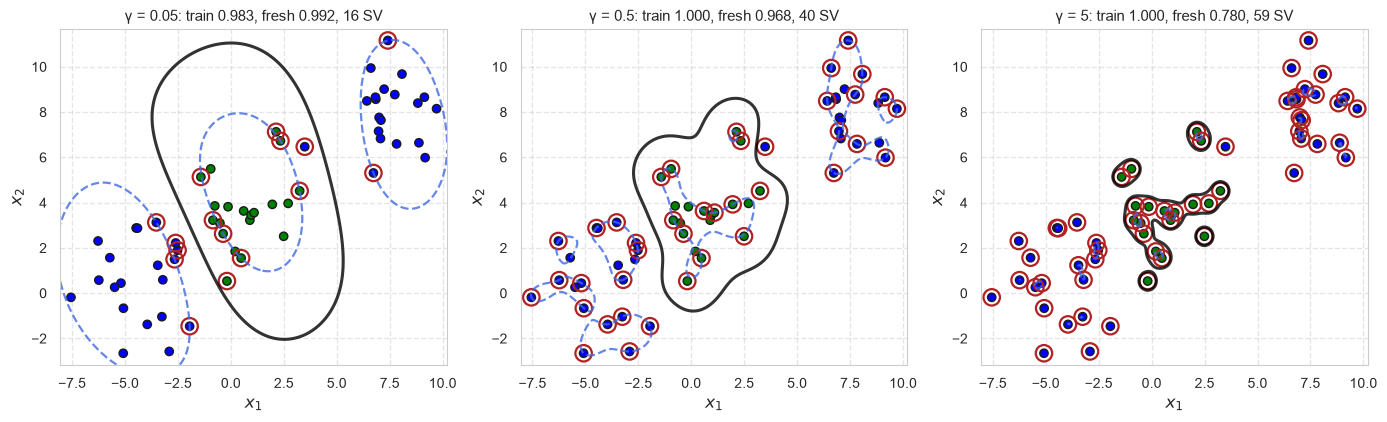

In [10]:
X_fresh, y_fresh3 = make_blobs(n_samples=600, centers=centers_h, cluster_std=1.5, random_state=4)   # same clusters, new points
y_fresh = np.where(y_fresh3 == 2, 1, y_fresh3)
xx_h, yy_h, grid_h = hp.create_2d_grid(X_h)
panels = {}
for gamma in (0.05, 0.5, 5):
    model = svm.SVC(kernel="rbf", C=1, gamma=gamma).fit(X_h, y_h)
    title = f"γ = {gamma}: train {model.score(X_h, y_h):.3f}, fresh {model.score(X_fresh, y_fresh):.3f}, {model.n_support_.sum()} SV"
    panels[title] = (X_h, y_h, xx_h, yy_h, model.decision_function(grid_h).reshape(xx_h.shape), model.support_vectors_)
hp.plot_svm_panels(panels, figsize=(14, 4.4))

### SVMs with More than Two Classes

- An SVM separates two classes. For $K > 2$ classes:
  - **One-versus-one**: fit $\binom{K}{2}$ SVMs, one for every pair of classes; predict the class that wins most pairwise votes.
  - **One-versus-all** (one-versus-rest): fit $K$ SVMs, class $k$ against all others; predict the class with the largest $y_k(\mathbf{x})$.
- scikit-learn's `SVC` uses one-versus-one internally; both strategies are also available as wrappers.

In [11]:
# The three clusters as three classes (before merging two of them)
for name, strategy in [("one-versus-one", OneVsOneClassifier(svm.SVC(kernel="linear"))),
                       ("one-versus-all", OneVsRestClassifier(svm.SVC(kernel="linear")))]:
    strategy.fit(X_h, y_h3)
    display(Markdown(f"{name}: {len(strategy.estimators_)} SVMs, training accuracy {strategy.score(X_h, y_h3):.3f}, "
                     f"accuracy on fresh points {strategy.score(X_fresh, y_fresh3):.3f}"))

one-versus-one: 3 SVMs, training accuracy 0.983, accuracy on fresh points 0.977

one-versus-all: 3 SVMs, training accuracy 0.967, accuracy on fresh points 0.958

## 5. Applied Case Study: Breast Cancer Recurrence

- 286 patients, 9 categorical features (age group, menopause, tumour size, …); target: recurrence of the cancer.
- Protocol: stratified train/test split; one-hot encoding inside the pipeline; $C$ and $\gamma$ of an RBF SVM chosen by 5-fold CV on the training data; one test evaluation next to baselines.
- Missing values (`?` in the data) are imputed with the most frequent category, also inside the pipeline.

In [12]:
# Load breast cancer dataset 
bc = pd.read_csv(hp.get_data_path("breast-cancer.csv"))
bc.head()


,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [13]:
bc.describe(include='all')

,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
count,286,286,286,286,286,286,286.000000,286,286,286
unique,2,6,3,11,7,3,NaN,2,6,2
top,no-recurrence-events,50-59,premeno,30-34,0-2,no,NaN,left,left_low,no
freq,201,96,150,60,213,222,NaN,152,110,218
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.048951,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.738217,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN


In [14]:
t_bc = (bc.recurrence == "recurrence-events").astype(int).to_numpy()            # 1 = recurrence (positive class)
X_bc = bc.drop(columns="recurrence").replace("?", np.nan)                        # "?" marks a missing value
X_train, X_test, t_train, t_test = train_test_split(X_bc, t_bc, test_size=0.25, random_state=1, stratify=t_bc)
display(Markdown(f"{len(t_bc)} patients, recurrence rate {t_bc.mean():.3f}; missing values per feature: "
                 + ", ".join(f"{c} {n}" for c, n in X_bc.isna().sum().items() if n)))

286 patients, recurrence rate 0.297; missing values per feature: node-caps 8, breast-quad 1

In [15]:
preprocess = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
svm_search = GridSearchCV(make_pipeline(preprocess, svm.SVC(kernel="rbf", class_weight="balanced")),
                          {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}, cv=folds, scoring="f1")
svm_search.fit(X_train, t_train)                        # encoder, imputer and SVM fitted on the training folds only
best = svm_search.best_index_
display(Markdown(f"Chosen {svm_search.best_params_}: CV $F_1$ {svm_search.best_score_:.3f} "
                 f"± {svm_search.cv_results_['std_test_score'][best]:.3f} (standard deviation over the 5 folds)"))

Chosen {'svc__C': 1, 'svc__gamma': 0.1}: CV $F_1$ 0.546 ± 0.106 (standard deviation over the 5 folds)

In [16]:
logistic_search = GridSearchCV(make_pipeline(preprocess, LogisticRegression(class_weight="balanced", max_iter=5000)),
                               {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=folds, scoring="f1").fit(X_train, t_train)
models = {
    "always 'no recurrence'": DummyClassifier(strategy="most_frequent").fit(X_train, t_train),
    "always 'recurrence'": DummyClassifier(strategy="constant", constant=1).fit(X_train, t_train),
    "logistic regression (CV)": logistic_search,
    "RBF SVM (CV)": svm_search,
}
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({"model": name, "test accuracy": mt.accuracy_score(t_test, pred),
                 "test F1 (recurrence)": mt.f1_score(t_test, pred, zero_division=0)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                   model  test accuracy  test F1 (recurrence)
  always 'no recurrence'          0.708                 0.000
     always 'recurrence'          0.292                 0.452
logistic regression (CV)          0.708                 0.553
            RBF SVM (CV)          0.708                 0.512


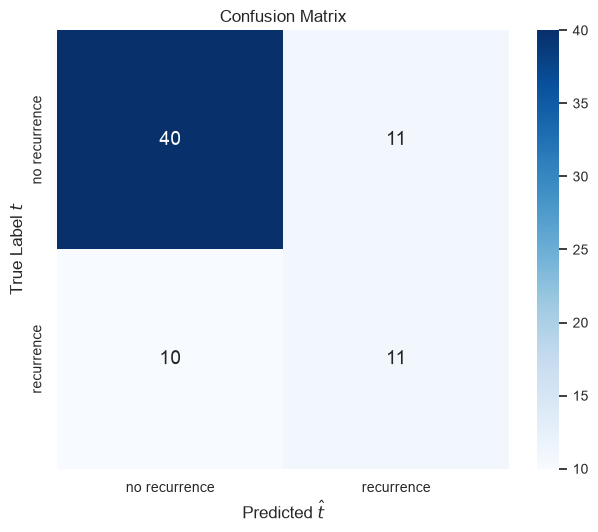

In [17]:
hp.plot_confusion_matrix(t_test, svm_search.predict(X_test), labels=["no recurrence", "recurrence"])

                   model  training AUC  test AUC
            RBF SVM (CV)         0.890     0.659
logistic regression (CV)         0.763     0.655
          RBF SVM, γ = 1         0.982     0.580


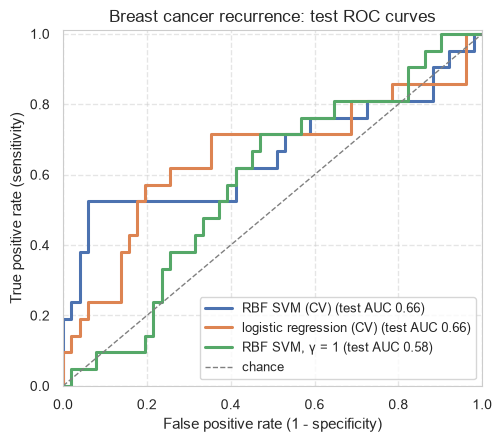

In [18]:
# ROC curves on training vs. test data: a flexible model looks excellent on its own training data
flexible = make_pipeline(preprocess, svm.SVC(kernel="rbf", C=10, gamma=1, class_weight="balanced")).fit(X_train, t_train)
roc, rows = {}, []
for name, model in [("RBF SVM (CV)", svm_search), ("logistic regression (CV)", logistic_search), ("RBF SVM, γ = 1", flexible)]:
    auc_train = mt.roc_auc_score(t_train, model.decision_function(X_train))
    auc_test = mt.roc_auc_score(t_test, model.decision_function(X_test))
    fpr, tpr, _ = mt.roc_curve(t_test, model.decision_function(X_test))
    roc[f"{name} (test AUC {auc_test:.2f})"] = (fpr, tpr)
    rows.append({"model": name, "training AUC": auc_train, "test AUC": auc_test})
print(pd.DataFrame(rows).round(3).to_string(index=False))
hp.plot_roc_curves(roc, title="Breast cancer recurrence: test ROC curves")

> 💡 **Key Takeaway:** Compare with the baselines and with the test, not the training, ROC curve: recurrence is hard to predict from these features, and a flexible kernel that looks excellent on its own training data does not generalize.

### Relationship to Logistic Regression

- The support vector classifier can be written as **loss + penalty**, with $t_n \in \{-1, +1\}$:

$$
\min_{\mathbf{w}, w_0} \sum_{n=1}^{N} \max\left(0,\; 1 - t_n y(\mathbf{x}_n)\right) + \lambda \|\mathbf{w}\|^2, \qquad \lambda = \frac{1}{2C}
$$

- The **hinge loss** $\max(0, 1 - t_n y(\mathbf{x}_n))$ is exactly zero for points beyond the margin: only the support vectors matter.
- Logistic regression minimizes the **logistic loss** $\ln(1 + e^{-t_n y(\mathbf{x}_n)})$ (the cross-entropy of Lecture 03 for targets $\pm 1$), which is never exactly zero but very similar in shape.
- Rule of thumb: when the classes are well separated, SVMs tend to do better; when they overlap a lot, logistic regression is often preferable and also gives probabilities.

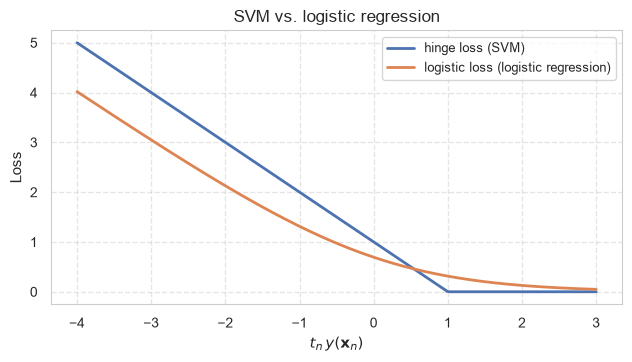

In [19]:
def hinge_loss(margin):
    """Hinge loss max(0, 1 - t y(x)) as a function of t y(x)."""
    return np.maximum(0, 1 - margin)

def logistic_loss(margin):
    """Logistic loss ln(1 + exp(-t y(x))) as a function of t y(x)."""
    return np.log(1 + np.exp(-margin))

margin = np.linspace(-4, 3, 200)
hp.plot_curves(margin, {"hinge loss (SVM)": hinge_loss(margin), "logistic loss (logistic regression)": logistic_loss(margin)},
               xlabel=r"$t_n\, y(\mathbf{x}_n)$", ylabel="Loss", title="SVM vs. logistic regression", figsize=(6.5, 3.8))

## 6. Algorithm Selection Card: Support Vector Machines (SVM)

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | Medium-sized tabular or high-dimensional datasets with intricate non-linear decision boundaries where feature count is high relative to sample size ($D \approx N$). |
| **Key Hyperparameters** | • Penalty $C$ on margin violations (large $C$ = narrow margin, close to a hard margin; small $C$ = wide, soft margin).<br>• Kernel: `linear`, `rbf`, `poly`.<br>• Kernel Coefficient $\gamma$ (`scale`, `auto`, float) for RBF/polynomial kernels. |
| **Interpretability vs. Capacity** | **Low Interpretability / High Capacity**: With RBF kernels, SVM is a highly flexible non-linear estimator; decision boundary is defined geometrically by support vectors. |
| **Critical Pitfalls** | • **Feature Scaling**: standardize features measured in different units (`StandardScaler` in a `Pipeline`); otherwise the kernel distances are distorted.<br>• **Overlapping classes**: little to gain over logistic regression, which also gives probabilities.<br>• **Scaling Limits**: Training time scales quadratically to cubically $\mathcal{O}(N^2 - N^3)$ with sample size; slow on $N > 50{,}000$. |

> 💡 **Key Takeaway:** SVMs maximize geometric margins to achieve strong theoretical generalization. Scale features measured in different units and tune $C$ and $\gamma$ jointly by cross-validation on the training data.